In [1]:
import pandas as pd

In [2]:
df_metadata = pd.read_csv('../data/processed/metadata_ad_control.csv')
df = pd.read_csv('../data/processed/data.csv')

In [3]:
geo_accession = list(df_metadata['geo_accession'])
id_ref = df['ID_REF']

# Get only AD and non-dementeds
df = df.loc[:, df.columns.isin(geo_accession)]
df['ID_REF'] = id_ref

In [4]:
# Replace index with ID
df.index = df['ID_REF']
df = df.drop(columns=['ID_REF'])
df = df.sort_index()

In [5]:
# Transpose so each probe becomes a column
df = df.T

In [6]:
# Total number of missing values
df.isna().sum().sum()

np.int64(701)

In [7]:
nan_max_per_probe = df.isna().sum(axis=0).max()
pct_nan_max_probe = nan_max_per_probe / df.shape[0] * 100

print(f'Maximum missing values per probe: {nan_max_per_probe}')
print(f'Percentage of all samples: {pct_nan_max_probe:.1f}%')

Maximum missing values per probe: 9
Percentage of all samples: 1.9%


In [8]:
nan_max_per_sample = df.isna().sum(axis=1).max()
pct_nan_max_sample = nan_max_per_sample / df.shape[1] * 100

print(f'Maximum missing values per sample: {nan_max_per_sample}')
print(f'Percentage of all probes: {pct_nan_max_sample:.1f}%')

Maximum missing values per sample: 80
Percentage of all probes: 0.2%


In [9]:
df.head()

ID_REF,10019475365,10019481149,10019495284,10019687586,10019713746,10019799479,10019809115,10019874890,10019903058,10019909307,...,10033669039,10033669040,10033669041,10033669042,10033669043,10033669045,10033669046,10033669047,10033669048,10033669049
GSM1423780,-0.016184,-0.017105,0.077440,0.033595,-0.001819,-0.065462,-0.042255,-0.000237,-0.051375,0.031249,...,-0.107363,-0.005318,-0.081350,0.123740,0.104146,0.114913,0.024853,-0.062032,-0.068883,0.170841
GSM1423781,0.027599,-0.023574,-0.058746,0.032914,0.032487,0.016333,0.003896,0.026999,0.237243,0.047474,...,-0.016103,0.045702,0.031939,0.027814,-0.010796,-0.219624,-0.001018,-0.042930,-0.072794,0.154764
GSM1423782,-0.089661,0.044863,-0.120759,-0.030928,-0.015073,-0.008490,0.005585,0.034198,0.291271,0.025229,...,0.000134,0.048495,-0.033006,0.089244,-0.031901,-0.205338,0.039534,-0.175094,-0.003799,0.359424
GSM1423783,-0.020493,0.003438,0.072692,-0.033051,-0.010303,-0.029326,-0.019656,0.023072,-0.023117,0.077798,...,-0.028737,0.086333,-0.016658,0.011806,-0.027000,-0.065482,0.031740,-0.037869,-0.046252,0.203776
GSM1423784,-0.051699,-0.064108,-0.051002,-0.049156,0.063070,0.020476,-0.038470,0.035463,-0.152237,0.083566,...,-0.063595,0.048858,-0.128627,0.041769,-0.036706,-0.085186,0.028517,-0.088991,0.010318,0.153241


In [10]:
median = df.apply(lambda x: x.median(), axis=1).rename('Median')
std = df.apply(lambda x: x.std(), axis=1).rename('Std')

stats_df = pd.merge(median, std, left_index=True, right_index=True)

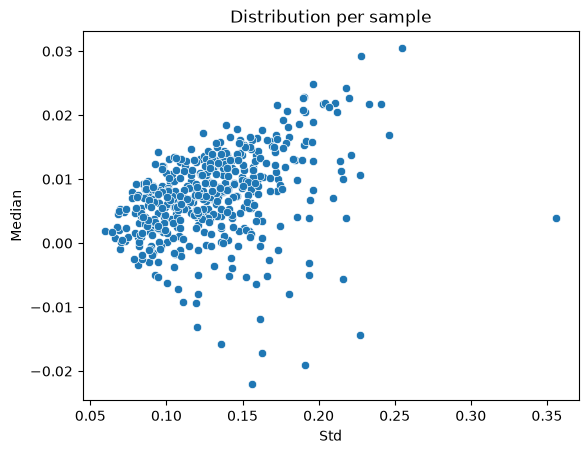

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.scatterplot(stats_df, x='Std', y='Median')
ax.set(title='Distribution per sample')
ax.figure.savefig('../figures/distribution_per_sample.png')

plt.show()

In [12]:
# Get first 2 outliers
outliers = stats_df.sort_values('Std', ascending=False).iloc[:2]

# Check group
group_outlier = df_metadata[df_metadata['geo_accession'] == outliers.iloc[0].name]

# Calculate percentage
mean_std = stats_df['Std'].mean()
max_mean = outliers.iloc[0]['Std'] / mean_std

print(f'Outlier is {max_mean:.1f} times the average\n')
print(f'Outlier info:\n{group_outlier}\n')

outliers

Outlier is 2.7 times the average

Outlier info:
     age_ch2 gender_ch2   disease_status_ch2 geo_accession
164       93     female  Alzheimer's disease    GSM1423944



,Median,Std
GSM1423944,0.003965,0.356016
GSM1424051,0.030546,0.254853


In [13]:
# Remove outlier
df = df.drop(index=outliers.iloc[0].name)

In [14]:
df_shape = df.shape[0] * df.shape[1]
min_max = ((df.values == 2) | (df.values == -2)).sum()
pct_min_max = min_max / df_shape * 100

print(f'Total matrix: {df_shape}')
print(f'Min = -2 or max = 2: {min_max}\n')

print(f'Percentage: {pct_min_max:.4}%')

Total matrix: 18304480
Min = -2 or max = 2: 5081

Percentage: 0.02776%


## Annot

In [15]:
annot = {}
count = 0

with open('../data/raw/GPL4372.annot') as file:
    for line in file:
        # Ignore header and get annot
        if not line.startswith('!') and not line.startswith('#') and not line.startswith('^'):
            line = line.split('\t')
            annot[count] = line
            count += 1

annot = pd.DataFrame(annot)
columns = annot.iloc[0]

# Get columns
annot.columns = columns

# # Remove "\n" from rows
annot = annot.replace(r'\n', '', regex=True)
annot = annot.drop(annot.index[0])

# First column as index
annot.index = annot['ID']
annot = annot.drop(columns=['ID'])


In [16]:
annot = annot.T
annot.head()

ID,Gene title,Gene symbol,Gene ID,UniGene title,UniGene symbol,UniGene ID,Nucleotide Title,GI,GenBank Accession,Platform_CLONEID,Platform_ORF,Platform_SPOTID,Chromosome location,Chromosome annotation,GO:Function,GO:Process,GO:Component,GO:Function ID,GO:Process ID,GO:Component ID
0,,,,,,,,,,,,,,,,,,,,
10025930146,,,,Transcribed locus,,Hs.570225,om25h03.s1 Soares_NFL_T_GBC_S1 Homo sapiens cD...,3075810,AA926913,,,,,,,,,,,
10025930335,"xeroderma pigmentosum, complementation group A",XPA,7507,"Xeroderma pigmentosum, complementation group A",XPA,Hs.654364,"Homo sapiens cDNA FLJ11599 fis, clone HEMBA100...",10432891,AK021661,,,,9q22.3,"Chromosome 9, NC_000009.10 (99477012..99499460...",damaged DNA binding///metal ion binding///nucl...,nucleotide-excision repair,nucleus,GO:0003684///GO:0046872///GO:0000166///GO:0005...,GO:0006289,GO:0005634
10025913794,hypothetical gene supported by NM_194304,LOC439911,439911,,,,Homo sapiens mRNA; cDNA DKFZp313L1514 (from cl...,21732601,AL832060,,,,10q11.21,Chromosome 10,,,,,,
10023807248,solute carrier family 35 (UDP-N-acetylglucosam...,SLC35A3,23443,,,,Homo sapiens solute carrier family 35 (UDP-N-a...,6912667,NM_012243,,SLC35A3,,1p21,"Chromosome 1, NC_000001.9 (100208128..100261594)",UDP-N-acetylglucosamine transmembrane transpor...,UDP-N-acetylglucosamine metabolic process///UD...,Golgi apparatus///Golgi membrane///integral to...,GO:0005462///GO:0005338///GO:0005351,GO:0006047///GO:0015788///GO:0015780,GO:0005794///GO:0000139///GO:0016021///GO:0016020
10023809851,katanin p60 subunit A-like 1,KATNAL1,84056,,,,Homo sapiens katanin p60 subunit A-like 1 (KAT...,62177111,NM_001014380,,KATNAL1,,13q12.3,"Chromosome 13, NC_000013.9 (29674767..29779584...",ATP binding///hydrolase activity///microtubule...,,microtubule,GO:0005524///GO:0016787///GO:0008568///GO:0017...,,GO:0005874


In [17]:
print(f'Data type index annot: {annot.index.inferred_type}')
print(f'Data type columns df: {df.columns.inferred_type}\n')

annot.index = pd.to_numeric(annot.index)

print(f'Data type index annot (AFTER): {annot.index.inferred_type}')

Data type index annot: string
Data type columns df: integer

Data type index annot (AFTER): integer


In [18]:
print(f'Annot shape: {annot.shape[0]}')

# Filter probes in annot to match df
df_probes = list(df.columns)
annot = annot.loc[annot.index.isin(df_probes)]

print(f'Data and annot with same ID: {annot.index.sort_values().equals(df.columns.sort_values())}')
print(f'Annot shape after match: {annot.shape[0]}')

Annot shape: 39302
Data and annot with same ID: True
Annot shape after match: 39280


In [19]:
median_probe = df.apply(lambda x: x.median(), axis=0).rename('Median')
std_probe = df.apply(lambda x: x.std(), axis=0).rename('Std')

stats_df_probe = pd.merge(median_probe, std_probe, left_index=True, right_index=True)

# Append std to annot
annot = pd.merge(annot, stats_df_probe['Std'], left_index=True, right_index=True)

In [20]:
print(f'Annot shape: {annot.shape[0]}\n')

# Keep only symbols not empty
annot = annot[annot['Gene symbol'] != '']
with_gene = annot.shape[0]
print(f'Probes with gene: {with_gene}')

# Keep the ones with one gene
annot = annot[annot['Gene symbol'].str.find('///') == -1]
more_than_one = annot.shape[0]
print(f'More than one gene: {with_gene - more_than_one}')

# Sort by standard deviation
annot = annot.sort_values('Std')

# Keep only last duplicate
annot = annot.drop_duplicates(['Gene symbol'], keep='last')
duplicated_gene = annot.shape[0]
print(f'Duplicated gene: {more_than_one - duplicated_gene}')

Annot shape: 39280

Probes with gene: 24134
More than one gene: 125
Duplicated gene: 4599


In [21]:
gene_symbol = dict(annot['Gene symbol'])

# Filter df based on annot
df = df.loc[:, df.columns.isin(gene_symbol.keys())]

# Rename columns using gene symbol
df = df.rename(columns=gene_symbol)

In [22]:
df.head()

ID_REF,OR2T6,DKFZp686D0972,NOTCH2NL,SPIRE1,HSP90AA5P,SEMA4C,LOC728217,PTK7,RAC3,EEF2K,...,SLC7A4,XIST,ABCB8,SLC4A5,ABCA6,CYP8B1,SLC6A13,NAT1,ABCC1,UBC
GSM1423780,0.031249,0.074265,0.252653,0.070166,-0.175990,0.048764,-0.009946,0.054477,-0.079832,0.036474,...,-0.050536,0.378551,-0.033335,-0.029184,-0.088403,-0.005318,-0.081350,0.104146,-0.068883,0.170841
GSM1423781,0.047474,-0.012425,0.018820,0.081982,-0.125693,0.121229,-0.136300,0.121011,0.053280,0.039189,...,0.025661,-1.773067,-0.029328,-0.087389,-0.077986,0.045702,0.031939,-0.010796,-0.072794,0.154764
GSM1423782,0.025229,0.032135,-0.099547,0.086942,0.064224,0.020113,0.054568,0.000783,0.009715,-0.023340,...,0.083952,-1.871089,-0.000676,-0.175118,-0.172610,0.048495,-0.033006,-0.031901,-0.003799,0.359424
GSM1423783,0.077798,0.039638,0.139135,0.048914,-0.135775,0.013053,-0.117995,0.204031,0.195881,0.113818,...,-0.128077,0.338872,0.026046,0.066593,0.127126,0.086333,-0.016658,-0.027000,-0.046252,0.203776
GSM1423784,0.083566,-0.144225,0.159344,0.142559,0.021567,0.101992,-0.070392,-0.109156,-0.128335,0.058792,...,-0.024543,0.432422,0.019393,-0.145825,0.006903,0.048858,-0.128627,-0.036706,0.010318,0.153241


In [23]:
# Check if all columns are unique
df.columns.is_unique

True

In [24]:
xist_df = pd.merge(df_metadata, df, left_on='geo_accession', right_index=True)[['geo_accession', 'XIST', 'gender_ch2']]

xist_df.groupby(['gender_ch2'])['XIST'].mean()

gender_ch2
female    0.295272
male     -1.711775
Name: XIST, dtype: float64

In [25]:
# Save new data with gene symbols
df.to_csv('../data/processed/data_symbol.csv')